# Landing Page A/B Experiment
## Business performance, statistical evidence, and recommendations

This project compares landing page **A (control)** with **B (treatment)** using conversion, average spend among buyers, and revenue per exposed user. It also examines traffic sources and user types to distinguish audience volume from conversion efficiency.

**Analysis plan:** validate the data; compare buyer spending; test conversion rates; examine traffic and user segments; visualize the findings; evaluate revenue per user; and make a business recommendation.

All reported treatment differences use **B − A**. Tests are two-sided at **α = 0.05**. Monetary amounts are expressed in **currency units (CU)** because the source does not specify a currency.

**Reproducibility:** place `landing_experiment.csv` beside this notebook, in `data/`, or in `/datasets/`, then select **Restart Kernel and Run All**. Alternatively, set `DATA_PATH` below. Required packages: pandas, numpy, matplotlib, seaborn, scipy, statsmodels, and IPython.

**Saved results:** the original CSV was not included with the notebook. Existing numerical results are retained from its saved outputs; categorical charts are redrawn from its exact saved counts. The two original spending-diagnostic figures are preserved, including their original Spanish labels, because their underlying observations are unavailable. Their code now uses English labels and replaces these images when run with the CSV. No individual-level data have been reconstructed. The narrative describes the original January 2026 experiment and should be reviewed if the input changes.

## Step 1: Load and validate the data
### Imports and configuration

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display

ALPHA = 0.05
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
DATA_PATH = None  # Optional: Path("/your/path/landing_experiment.csv")
OUTPUT_DIR = Path("outputs")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

In [ ]:
candidates = ([Path(DATA_PATH)] if DATA_PATH is not None else [
    Path("landing_experiment.csv"), Path("data/landing_experiment.csv"),
    Path("/datasets/landing_experiment.csv")
])
input_path = next((path for path in candidates if path.is_file()), None)
if input_path is None:
    raise FileNotFoundError(
        "Source CSV not found. Set DATA_PATH or place landing_experiment.csv "
        "beside this notebook, in data/, or in /datasets/."
    )
raw_df = pd.read_csv(input_path, dtype={"user_id": "string"})
# Translate the schema without modifying the source file.
column_aliases = {"dispositivo": "device", "gasto": "spend"}
for source_name, target_name in column_aliases.items():
    if source_name in raw_df and target_name in raw_df:
        raise ValueError(f"Ambiguous schema: both {source_name} and {target_name} exist.")
df = raw_df.rename(columns=column_aliases).copy()
required_columns = ["user_id", "date", "landing", "region", "device",
                    "traffic_source", "user_type", "converted", "spend"]
missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")
for column in ["landing", "region", "device", "traffic_source", "user_type"]:
    df[column] = df[column].astype("string").str.strip()
df["region"] = df["region"].replace({
    "Norte": "North", "Centro": "Central", "Sur": "South",
    "Occidente": "West", "Oriente": "East"
})
df["user_type"] = df["user_type"].replace({"Nuevo": "New", "Recurrente": "Returning"})
display(df.head())

,user_id,date,landing,region,device,traffic_source,user_type,converted,spend
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,North,Mobile,Email,Returning,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,West,Mobile,Organic,New,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Central,Mobile,Organic,New,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Central,Mobile,Ads,New,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,South,Mobile,Organic,New,0,0.00


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   device     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   spend           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


### Data dictionary

| Column | Meaning |
|---|---|
| `user_id` | User identifier; one row per exposed user is required. |
| `date` | Exposure date. |
| `landing` | Assigned page: A or B. |
| `region` | Geographic region. |
| `device` | Device category; originally `dispositivo`. |
| `traffic_source` | Acquisition channel. |
| `user_type` | New or Returning, using the source classification. |
| `converted` | Purchase indicator: 0 or 1. |
| `spend` | Recorded amount spent in CU; originally `gasto`. |

The original preview reports **40,000 rows and nine columns**, with no missing values. The date initially requires conversion from text. This first inspection alone does not establish data quality; the following checks validate identifiers, categories, dates, spending, and allocation.

In [ ]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="raise")
df["converted"] = pd.to_numeric(df["converted"], errors="raise")
df["spend"] = pd.to_numeric(df["spend"], errors="raise")
if df.empty or df[required_columns].isna().any().any():
    raise ValueError("The dataset must be nonempty and complete in all required columns.")
if df["user_id"].astype(str).str.strip().eq("").any() or df["user_id"].duplicated().any():
    raise ValueError("User identifiers must be nonblank and unique; investigate repeated users.")
if not df["converted"].isin([0, 1]).all():
    raise ValueError("converted must contain only 0 and 1.")
if not np.isfinite(df["spend"]).all() or (df["spend"] < 0).any():
    raise ValueError("Spending must be finite and nonnegative.")
if not df["converted"].eq(df["spend"].gt(0).astype(int)).all():
    raise ValueError("Conversion and positive spending disagree; investigate before analysis.")
expected_categories = {
    "landing": {"A", "B"}, "region": {"North", "Central", "South", "West", "East"},
    "device": {"Mobile", "Desktop"}, "traffic_source": {"Organic", "Ads", "Email", "Referral"},
    "user_type": {"New", "Returning"}
}
for column, expected in expected_categories.items():
    unexpected = set(df[column].unique()) - expected
    if unexpected:
        raise ValueError(f"Unexpected {column} categories: {unexpected}")
if set(df["landing"].unique()) != {"A", "B"}:
    raise ValueError("Both A and B must be present.")
df["converted"] = df["converted"].astype("int64")
print(f"Rows: {len(df):,} | Unique users: {df['user_id'].nunique():,}")
print(f"Duplicate users: {df['user_id'].duplicated().sum()} | Missing required values: {df[required_columns].isna().sum().sum()}")
print(f"Exposure dates: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Distinct dates: {df['date'].nunique()}")
display(df["date"].describe())
display(df["spend"].describe())
spending_check = pd.crosstab(df["converted"], df["spend"].gt(0), margins=True, margins_name="Total")
display(spending_check.rename(columns={False: "Zero spend", True: "Positive spend"}))

Rows: 40,000 | Unique users: 40,000
Duplicate users: 0 | Missing required values: 0
Exposure dates: 2026-01-01 to 2026-01-28
Distinct dates: 28
Spending: mean 9.325554 CU; median 0; standard deviation 25.667986; maximum 303.68.
Conversion/spending cross-tabulation:
              Zero spend  Positive spend  Total
Not converted      34294               0  34294
Converted              0            5706   5706
Total              34294            5706  40000


count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: spend, dtype: float64

### Spending distribution and outliers
High spending is flagged for investigation, not automatically removed. The primary analysis retains all valid observations.

Buyer spending quantiles:
0.500     59.86
0.750     80.37
0.900    106.58
0.950    123.54
0.990    164.34
0.999    226.15
Maximum: 303.68

IQR: 37.42
Upper fence (Q3 + 1.5·IQR): 136.50
Outliers: 166 (2.91% of buyers)

Mean with outliers:  65.37
Mean without outliers:  62.42
Median:             59.86


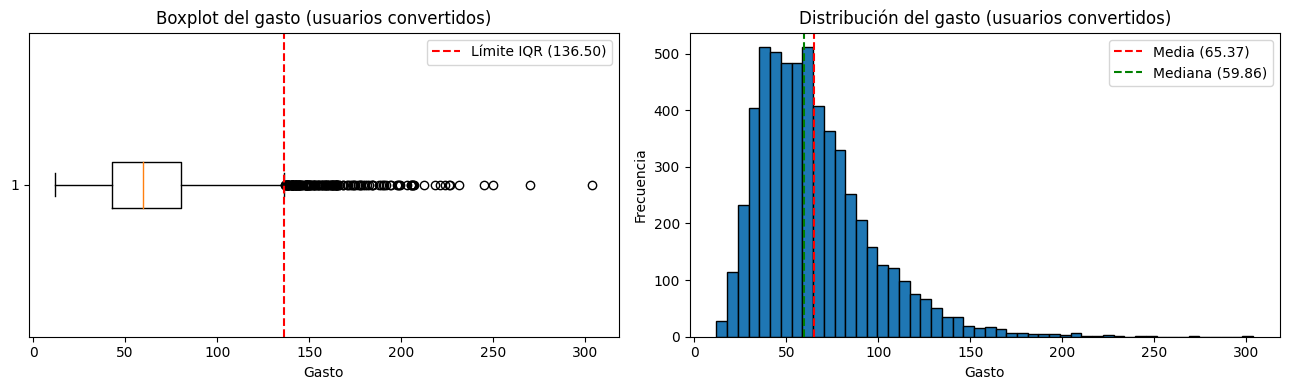

In [ ]:
buyer_spend = df.loc[df["converted"].eq(1), "spend"]
if len(buyer_spend) < 2:
    raise ValueError("At least two buyers are required for spending diagnostics.")
print("Buyer spending quantiles (CU):")
display(buyer_spend.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999]).round(2))
q1, q3 = buyer_spend.quantile([0.25, 0.75])
buyer_iqr = q3 - q1
upper_fence = q3 + 1.5 * buyer_iqr
outlier_mask = buyer_spend.gt(upper_fence)
print(f"Maximum: {buyer_spend.max():.2f} | IQR: {buyer_iqr:.2f} | Upper fence: {upper_fence:.2f}")
print(f"Upper outliers: {outlier_mask.sum():,} ({outlier_mask.mean():.2%})")
print(f"Mean, all buyers: {buyer_spend.mean():.2f}; without upper outliers: {buyer_spend[~outlier_mask].mean():.2f}; median: {buyer_spend.median():.2f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(buyer_spend, vert=False)
axes[0].axvline(upper_fence, color="red", linestyle="--", label=f"IQR fence ({upper_fence:.2f})")
axes[0].set(title="Buyer spending: box plot", xlabel="Spending (CU)")
axes[0].legend()
axes[1].hist(buyer_spend, bins=50, edgecolor="black")
axes[1].axvline(buyer_spend.mean(), color="red", linestyle="--", label="Mean")
axes[1].axvline(buyer_spend.median(), color="green", linestyle="--", label="Median")
axes[1].set(title="Buyer spending distribution", xlabel="Spending (CU)", ylabel="Frequency")
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretation.** Buyer spending is right-skewed: mean **65.37 CU**, median **59.86 CU**, and range **12.12–303.68 CU**. The IQR rule flags **166 buyers (2.91%)** above **136.50 CU**; removing them lowers the mean to **62.42 CU**. These observations are retained unless there is evidence of a recording error.

*The saved diagnostic image above is preserved from the original run. Its English plotting code will regenerate it when the source CSV is available.*

In [ ]:
for column in expected_categories:
    print(f"\nDistribution of {column}:")
    display(df[column].value_counts(dropna=False))


Distribution of landing:
B    20018
A    19982
Name: landing, dtype: int64

Distribution of region:
North        11166
Central        9613
South           8039
West     6398
East       4784
Name: region, dtype: int64

Distribution of device:
Mobile     24829
Desktop    15171
Name: device, dtype: int64

Distribution of traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Distribution of user_type:
New         26033
Returning    13967
Name: user_type, dtype: int64


### Allocation and observed group composition
The sample-ratio mismatch (SRM) test assumes a planned **50:50 allocation**. Confirm that assumption against the experimental design. Balance checks describe observed composition; nonsignificant results do not prove successful randomization or independence.

In [ ]:
group_column = "landing"
balance_columns = ["region", "device", "traffic_source", "user_type"]
group_counts = df[group_column].value_counts().reindex(["A", "B"])
srm_stat, srm_p = stats.chisquare(group_counts, f_exp=np.repeat(len(df) / 2, 2))
display(group_counts.rename("Users").to_frame())
print(f"SRM chi-square: {srm_stat:.4f} | p-value: {srm_p:.4f}")
print("No sample-ratio mismatch detected." if srm_p >= ALPHA else "Possible sample-ratio mismatch: investigate allocation.")
balance_rows = []
for column in balance_columns:
    counts = pd.crosstab(df[column], df[group_column]).reindex(columns=["A", "B"])
    composition = counts.div(counts.sum(axis=0), axis=1) * 100
    composition["Difference B − A (pp)"] = composition["B"] - composition["A"]
    display(composition.round(2))
    balance_stat, balance_p, _, _ = stats.chi2_contingency(counts)
    balance_rows.append({"Variable": column,
                         "Maximum absolute difference (pp)": composition["Difference B − A (pp)"].abs().max(),
                         "p-value": balance_p, "Imbalance detected": balance_p < ALPHA})
balance_summary = pd.DataFrame(balance_rows)
display(balance_summary.round(4))

✅ Page column: 'landing'
✅ Composition variables: ['region', 'device', 'traffic_source', 'user_type']

📊 Group sizes:
A    19982
B    20018
SRM chi-square: 0.0324 | p-value: 0.8572
✅ No sample-ratio mismatch detected

📌 region (% within each page)


landing,A,B,Difference B − A (pp)
region,,,
Central,24.13,23.93,-0.20
North,27.79,28.04,0.25
West,16.19,15.80,-0.40
East,11.56,12.36,0.81
South,20.33,19.87,-0.46


📌 device (% within each page)


landing,A,B,Difference B − A (pp)
device,,,
Desktop,37.89,37.97,0.08
Mobile,62.11,62.03,-0.08


📌 traffic_source (% within each page)


landing,A,B,Difference B − A (pp)
traffic_source,,,
Ads,29.93,29.74,-0.19
Email,15.45,15.17,-0.28
Organic,45.00,44.93,-0.07
Referral,9.62,10.16,0.54


📌 user_type (% within each page)


landing,A,B,Difference B − A (pp)
user_type,,,
New,65.02,65.15,0.13
Returning,34.98,34.85,-0.13


,Variable,Maximum difference (pp),p-value,No imbalance detected
0,region,0.8085,0.0951,✅ Yes
1,device,0.0767,0.8825,✅ Yes
2,traffic_source,0.5372,0.3119,✅ Yes
3,user_type,0.1279,0.7966,✅ Yes


### Data-quality findings

- The dataset contains **40,000 unique users** over **January 1–28, 2026**, with no missing values, duplicate identifiers, negative spending, or conversion–spending inconsistencies in the saved checks.
- A has **19,982 users (49.955%)** and B has **20,018 (50.045%)**. SRM **p = 0.8572**; composition checks by region, device, traffic source, and user type all have **p > 0.05**. No imbalance was detected in these checks.
- There are **5,706 conversions (14.265%)**; **85.735%** of users did not buy. Revenue per exposed user is **9.33 CU** overall, compared with **65.37 CU** per buyer.
- North is the largest region (**11,166 users**); Mobile accounts for **24,829 users (62.07%)**; Organic is the largest channel (**17,987 users**); New users account for **26,033 (65.08%)**.

The data are suitable for the planned analyses subject to the experimental-design assumptions. Unique user IDs and one-page assignment support the intended unit of analysis but do not, by themselves, prove statistical independence.

### Export the cleaned dataset
The export includes every validated row and preserves extra source columns. It uses English column names and category labels, ISO dates, UTF-8 encoding, and no pandas index column. Valid high-spend observations are retained; no rows are silently dropped. The CSV is written only after validation succeeds.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
clean_path = OUTPUT_DIR / "landing_experiment_clean.csv"
clean_df = df.copy()
clean_df.to_csv(clean_path, index=False, encoding="utf-8", date_format="%Y-%m-%d")
# Confirm a full round trip, including identifiers, dates, values, and column order.
restored_df = pd.read_csv(clean_path, dtype={"user_id": df["user_id"].dtype})
restored_df["date"] = pd.to_datetime(restored_df["date"], format="%Y-%m-%d")
pd.testing.assert_frame_equal(
    clean_df.reset_index(drop=True), restored_df.reset_index(drop=True),
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12
)
print(f"Saved and verified {len(clean_df):,} rows and {clean_df.shape[1]} columns: {clean_path.resolve()}")

## Step 2: Compare average spending among buyers
This section conditions on conversion; it does **not** estimate revenue per exposed user. Welch’s two-sample t-test compares mean buyer spending without assuming equal variances.

**H₀:** μA = μB. **H₁:** μA ≠ μB. Use a two-sided test at α = 0.05 and report the mean difference as B − A. Because conversion can itself be affected by treatment, buyer-only differences are conditional comparisons and should not be treated as an unconditional causal treatment effect.

In [ ]:
buyer_spend_a = df.loc[df["landing"].eq("A") & df["converted"].eq(1), "spend"]
buyer_spend_b = df.loc[df["landing"].eq("B") & df["converted"].eq(1), "spend"]
if min(len(buyer_spend_a), len(buyer_spend_b)) < 2:
    raise ValueError("At least two buyers per page are required.")
buyer_summary = pd.DataFrame({"Page A": buyer_spend_a.describe(), "Page B": buyer_spend_b.describe()}).T
display(buyer_summary.round(2))
buyer_mean_a, buyer_mean_b = buyer_spend_a.mean(), buyer_spend_b.mean()
buyer_difference = buyer_mean_b - buyer_mean_a
buyer_t, buyer_p = stats.ttest_ind(buyer_spend_a, buyer_spend_b, equal_var=False)
print(f"Mean difference B − A: {buyer_difference:.2f} CU")
print(f"Welch t (A first): {buyer_t:.4f}; p-value: {buyer_p:.2e}")

,count,mean,std,min,25%,50%,75%,max
Page A,2512.0,61.09,28.88,12.12,40.61,55.84,74.84,303.68
Page B,3194.0,68.75,32.00,12.98,45.21,62.57,84.28,249.99


🔗 USER ASSIGNMENT
Unique buyers: 5,706 of 5,706 records
Users assigned to both pages: 0
✅ No repeated or cross-assigned users detected

📐 DISTRIBUTION SHAPE
Page A: n = 2,512 | skewness = 1.67 | mean = 61.09 | median = 55.84
Page B: n = 3,194 | skewness = 1.20 | mean = 68.75 | median = 62.57

📊 VARIANCES (Levene)
Standard deviation A: 28.88 | Standard deviation B: 32.00
Statistic: 29.1765 | p-value: 6.88e-08
➡️ Unequal variances: Welch is appropriate

🚨 UPPER OUTLIERS (IQR rule)
Page A: fence = 126.17 | outliers = 71 (2.83%) | maximum = 303.68
Page B: fence = 142.88 | outliers = 89 (2.79%) | maximum = 249.99


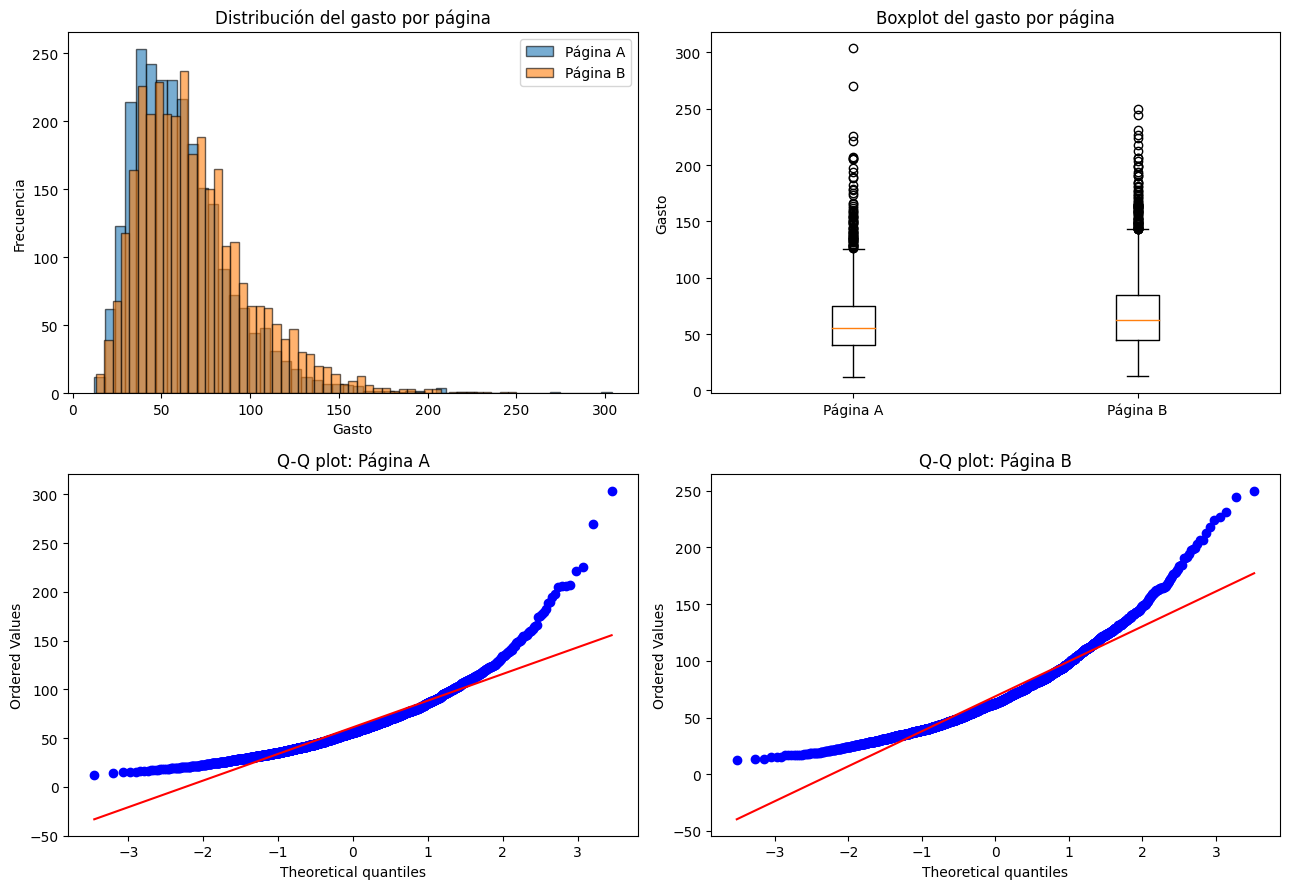

In [ ]:
print(f"Users assigned to both pages: {(df.groupby('user_id')['landing'].nunique() > 1).sum()}")
buyer_fences = {}
for label, values in [("A", buyer_spend_a), ("B", buyer_spend_b)]:
    q1, q3 = values.quantile([0.25, 0.75])
    buyer_fences[label] = q3 + 1.5 * (q3 - q1)
    print(f"Page {label}: n={len(values):,}; skewness={stats.skew(values):.2f}; "
          f"mean={values.mean():.2f}; median={values.median():.2f}; SD={values.std():.2f}; "
          f"upper fence={buyer_fences[label]:.2f}; outliers={(values > buyer_fences[label]).sum()}")
levene_stat, levene_p = stats.levene(buyer_spend_a, buyer_spend_b)
print(f"Levene statistic={levene_stat:.4f}; p-value={levene_p:.2e}")
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for label, values in [("Page A", buyer_spend_a), ("Page B", buyer_spend_b)]:
    axes[0, 0].hist(values, bins=50, alpha=0.6, label=label, edgecolor="black")
axes[0, 0].set(title="Buyer spending by page", xlabel="Spending (CU)", ylabel="Frequency")
axes[0, 0].legend()
axes[0, 1].boxplot([buyer_spend_a, buyer_spend_b], labels=["Page A", "Page B"])
axes[0, 1].set(title="Buyer spending: box plots", ylabel="Spending (CU)")
for ax, label, values in [(axes[1, 0], "A", buyer_spend_a), (axes[1, 1], "B", buyer_spend_b)]:
    stats.probplot(values, dist="norm", plot=ax)
    ax.set_title(f"Normal Q–Q plot: Page {label}")
plt.tight_layout()
plt.show()

**Assumptions and diagnostics.** No user appears in both pages in the saved checks. Buyer spending is right-skewed (A: **1.67**; B: **1.20**), and approximately **2.8%** of buyers in each group exceed the group-specific upper IQR fence. Levene’s test gives **p = 6.88 × 10⁻⁸**, supporting the use of unequal-variance inference. With more than 2,500 buyers per group, Welch’s approximation is reasonable; the robustness checks below assess sensitivity.

*The saved four-panel image is preserved from the original run; running the code regenerates its labels in English.*

In [ ]:
buyer_rng = np.random.default_rng(RANDOM_SEED)
buyer_boot_differences = np.empty(N_BOOTSTRAP)
buyer_array_a, buyer_array_b = buyer_spend_a.to_numpy(), buyer_spend_b.to_numpy()
for iteration in range(N_BOOTSTRAP):
    buyer_boot_differences[iteration] = (
        buyer_rng.choice(buyer_array_b, len(buyer_array_b), replace=True).mean()
        - buyer_rng.choice(buyer_array_a, len(buyer_array_a), replace=True).mean()
    )
buyer_boot_ci = np.percentile(buyer_boot_differences, [2.5, 97.5])
buyer_u, buyer_mw_p = stats.mannwhitneyu(buyer_spend_a, buyer_spend_b, alternative="two-sided")
buyer_trimmed_a = buyer_spend_a[buyer_spend_a <= buyer_fences["A"]]
buyer_trimmed_b = buyer_spend_b[buyer_spend_b <= buyer_fences["B"]]
trimmed_t, trimmed_p = stats.ttest_ind(buyer_trimmed_a, buyer_trimmed_b, equal_var=False)
buyer_robustness = pd.DataFrame({
    "Method": ["Welch: all buyers", "Bootstrap 95% CI: B − A", "Mann–Whitney U", "Welch: excluding upper outliers"],
    "Result": [f"Difference: {buyer_difference:.2f} CU", f"[{buyer_boot_ci[0]:.2f}, {buyer_boot_ci[1]:.2f}] CU",
               f"Median A: {buyer_spend_a.median():.2f}; B: {buyer_spend_b.median():.2f}",
               f"Difference: {buyer_trimmed_b.mean() - buyer_trimmed_a.mean():.2f} CU"],
    "p-value": [f"{buyer_p:.2e}", "Not applicable", f"{buyer_mw_p:.2e}", f"{trimmed_p:.2e}"]
})
display(buyer_robustness)

,Method,Result,p-value,Significant?
0,Welch (original),Difference = 7.66,3.63e-21,✅ Yes
1,Bootstrap 95% CI (B − A),"[6.10, 9.23]",Not applicable,✅ Yes
2,Mann-Whitney U,Median A = 55.84 | Median B = 62.57,1.04e-21,✅ Yes
3,Welch without upper outliers,Difference = 7.61,9.49e-29,✅ Yes


Mann–Whitney tests a rank/distribution contrast, not the same mean difference as Welch, and is not generally a test of medians without additional distributional assumptions. Outlier exclusion changes the target population; it is a sensitivity analysis, not the primary result.

In [ ]:
buyer_n_a, buyer_n_b = len(buyer_spend_a), len(buyer_spend_b)
buyer_var_mean_a = buyer_spend_a.var(ddof=1) / buyer_n_a
buyer_var_mean_b = buyer_spend_b.var(ddof=1) / buyer_n_b
buyer_se = np.sqrt(buyer_var_mean_a + buyer_var_mean_b)
buyer_welch_df = (buyer_var_mean_a + buyer_var_mean_b)**2 / (
    buyer_var_mean_a**2 / (buyer_n_a - 1) + buyer_var_mean_b**2 / (buyer_n_b - 1)
)
buyer_welch_ci = stats.t.interval(0.95, df=buyer_welch_df, loc=buyer_difference, scale=buyer_se)
print(f"Mean A: {buyer_mean_a:.2f} CU; mean B: {buyer_mean_b:.2f} CU")
print(f"Difference B − A: {buyer_difference:+.2f} CU")
print(f"Welch 95% CI: [{buyer_welch_ci[0]:+.2f}, {buyer_welch_ci[1]:+.2f}] CU")
print("Reject H0." if buyer_p < ALPHA else "Do not reject H0.")
print("The t statistic is computed as A − B because A is passed first; the reported effect is B − A.")

Mean A: 61.09 CU; mean B: 68.75 CU
Difference B − A: +7.66 CU
Welch 95% CI: [+6.08, +9.24] CU
Welch t (A first): -9.4810; p-value: 3.63e-21
Reject H0.


### Buyer-spending conclusion

| Metric | Page A | Page B |
|---|---:|---:|
| Buyers | 2,512 | 3,194 |
| Average spend (CU per buyer) | 61.09 | 68.75 |
| Median spend (CU per buyer) | 55.84 | 62.57 |

B’s buyers spent **7.66 CU more on average (+12.5%)**, with a Welch 95% CI of **[6.08, 9.24] CU** and **p = 3.63 × 10⁻²¹**. The bootstrap CI **[6.10, 9.23] CU**, the rank comparison, and Welch’s sensitivity analysis excluding upper outliers support the same overall direction.

This is a favorable conditional spending result. Conversion and revenue per exposed user must also be evaluated before selecting a page.

## Step 3: Compare conversion rates
**H₀:** pA = pB. **H₁:** pA ≠ pB. Use a two-sided two-proportion z-test at α = 0.05. Check that each group has at least ten conversions and ten non-conversions, as well as unique user records and one-page assignment.

In [ ]:
conversion_summary = df.groupby("landing")["converted"].agg(users="size", conversions="sum").reindex(["A", "B"])
conversion_summary["conversion_rate"] = conversion_summary["conversions"] / conversion_summary["users"]
display(conversion_summary)
conversion_counts = conversion_summary["conversions"].to_numpy()
exposure_counts = conversion_summary["users"].to_numpy()
if not ((conversion_counts >= 10) & (exposure_counts - conversion_counts >= 10)).all():
    raise ValueError("The normal-approximation count condition is not met.")
if df["user_id"].duplicated().any() or (df.groupby("user_id")["landing"].nunique() > 1).any():
    raise ValueError("Repeated users or cross-page assignments require investigation.")
conversion_z, conversion_p = proportions_ztest(conversion_counts, exposure_counts, alternative="two-sided")
conversion_rate_a, conversion_rate_b = conversion_summary["conversion_rate"]
conversion_difference = conversion_rate_b - conversion_rate_a
conversion_lift_pct = conversion_difference / conversion_rate_a * 100
conversion_se = np.sqrt(conversion_rate_a * (1 - conversion_rate_a) / exposure_counts[0]
                        + conversion_rate_b * (1 - conversion_rate_b) / exposure_counts[1])
conversion_ci = conversion_difference + np.array([-1, 1]) * stats.norm.ppf(0.975) * conversion_se
print(f"Conversion A: {conversion_rate_a:.2%}; B: {conversion_rate_b:.2%}")
print(f"Difference B − A: {conversion_difference * 100:+.2f} pp; relative lift: {conversion_lift_pct:+.2f}%")
print(f"95% CI: [{conversion_ci[0] * 100:.2f}, {conversion_ci[1] * 100:.2f}] pp")
print(f"z (A first): {conversion_z:.4f}; p-value: {conversion_p:.2e}")
print("Reject H0." if conversion_p < ALPHA else "Do not reject H0.")

         Users  Conversions  Conversion rate
Page A   19982         2512           12.57%
Page B   20018         3194           15.96%
Non-conversions: A = 17,470; B = 16,824. Normal-approximation count condition met.
Difference B − A: +3.38 pp; relative lift: +26.92%
95% CI: [2.70, 4.07] pp
z (A first): -9.6774; p-value: 3.76e-22
Reject H0.


### Conversion conclusion
B converted **15.96%** of exposed users, compared with **12.57%** for A. The difference is **+3.38 percentage points**, a **26.92% relative increase**, with a 95% CI of **[2.70, 4.07] percentage points**. The z statistic is negative because A is passed first.

At these observed rates, B would produce approximately **34 additional conversions per 1,000 exposed users**, if the rates persisted. This is a conditional projection, not a guaranteed future outcome. The result supports B, alongside the buyer-spending result; revenue per exposed user will provide the combined economic measure.

## Step 4: Examine traffic source and conversion
**H₀:** traffic source and conversion are independent. **H₁:** an association exists. Use a chi-square independence test across Organic, Ads, Email, and Referral. Distinguish the number of conversions from the conversion rate, inspect expected frequencies, and quantify association using Cramér’s V. Channel comparisons are observational.

In [ ]:
traffic_counts = pd.crosstab(df["traffic_source"], df["converted"]).reindex(columns=[0, 1], fill_value=0)
traffic_percentages = traffic_counts.div(traffic_counts.sum(axis=1), axis=0) * 100
display(traffic_counts)
display(traffic_percentages.round(2))
traffic_chi2, traffic_p, traffic_dof, traffic_expected = stats.chi2_contingency(traffic_counts)
traffic_v = np.sqrt(traffic_chi2 / (traffic_counts.to_numpy().sum() * (min(traffic_counts.shape) - 1)))
print(f"Chi-square: {traffic_chi2:.4f}; p-value: {traffic_p:.6f}; df: {traffic_dof}")
print(f"Minimum expected count: {traffic_expected.min():.2f}; cells below 5: {(traffic_expected < 5).sum()}")
print(f"Cramér's V: {traffic_v:.4f}")
print("Reject H0 at the unadjusted 5% level." if traffic_p < ALPHA else "Do not reject H0.")
if (traffic_expected < 5).any():
    print("Caution: sparse expected counts; the chi-square approximation requires review.")

,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


,0,1
traffic_source,,
Ads,85.26,14.74
Email,85.01,14.99
Organic,86.21,13.79
Referral,86.12,13.88


Chi-square: 8.6621; p-value: 0.034138; df: 3
Minimum expected count: 564.18; cells below 5: 0
Cramér's V: 0.0147


In [ ]:
def segment_summary(counts):
    summary = pd.DataFrame({"Users": counts.sum(axis=1), "Not converted": counts[0], "Conversions": counts[1]})
    summary["Conversion rate (%)"] = summary["Conversions"] / summary["Users"] * 100
    summary["Share of conversions (%)"] = summary["Conversions"] / summary["Conversions"].sum() * 100
    return summary.sort_values("Conversion rate (%)", ascending=False)

traffic_summary = segment_summary(traffic_counts)
display(traffic_summary.round(2))
print(f"Highest observed rate: {traffic_summary['Conversion rate (%)'].idxmax()}")
print(f"Most conversions: {traffic_summary['Conversions'].idxmax()}")

,Users,Not converted,Conversions,Conversion rate (%),Share of conversions (%)
traffic_source,,,,,
Email,6123,5205,918,14.99,16.09
Ads,11935,10176,1759,14.74,30.83
Referral,3955,3406,549,13.88,9.62
Organic,17987,15507,2480,13.79,43.46


### Traffic-source conclusion

The chi-square test gives **χ² = 8.6621**, **3 degrees of freedom**, and **p = 0.03414**; the minimum expected count is **564.18**. Cramér’s **V = 0.0147**, indicating a very small observed association.

| Channel | Conversions | Conversion rate |
|---|---:|---:|
| Email | 918 | 14.99% |
| Ads | 1,759 | 14.74% |
| Referral | 549 | 13.88% |
| Organic | 2,480 | 13.79% |

Email has the highest observed rate, while Organic contributes **43.46%** of all conversions. The highest-to-lowest rate gap is about **1.20 pp**. The global test is significant at the **unadjusted** 5% level but does not establish that Email outperforms any particular channel. Specific comparisons require appropriate multiple-testing control.

Treat this as exploratory evidence: assess acquisition cost, revenue, and profitability before reallocating marketing spend. The association does not establish causation, and its nominal significance is sensitive to how multiple hypotheses are handled.

## Step 5: Examine user type and conversion
**H₀:** user type and conversion are independent. **H₁:** they are associated. Compare New and Returning users using the source labels; Returning does not necessarily mean that a user purchased during this experiment. The exact business rules behind these labels are not documented here.

Use the chi-square test with Yates’ continuity correction for the 2 × 2 table, matching the original analysis. Also report Cramér’s V from the uncorrected Pearson statistic, the standard effect-size definition.

In [ ]:
user_counts = pd.crosstab(df["user_type"], df["converted"]).reindex(columns=[0, 1], fill_value=0)
user_percentages = user_counts.div(user_counts.sum(axis=1), axis=0) * 100
display(user_counts)
display(user_percentages.round(2))
user_summary = segment_summary(user_counts)
display(user_summary.round(2))
segment_page_rates = pd.crosstab(df["user_type"], df["landing"], values=df["converted"], aggfunc="mean") * 100
display(segment_page_rates.round(2))
user_chi2, user_p, user_dof, user_expected = stats.chi2_contingency(user_counts, correction=True)
user_pearson_chi2 = stats.chi2_contingency(user_counts, correction=False)[0]
user_v = np.sqrt(user_pearson_chi2 / (user_counts.to_numpy().sum() * (min(user_counts.shape) - 1)))
print(f"Chi-square (Yates corrected): {user_chi2:.4f}; p-value: {user_p:.6f}; df: {user_dof}")
print(f"Minimum expected count: {user_expected.min():.2f}; cells below 5: {(user_expected < 5).sum()}")
print(f"Cramér's V (uncorrected Pearson): {user_v:.4f}")
print("Reject H0." if user_p < ALPHA else "Do not reject H0.")

,0,1
user_type,,
New,22295,3738
Returning,11999,1968


,0,1
user_type,,
New,85.64,14.36
Returning,85.91,14.09


,Users,Not converted,Conversions,Conversion rate (%),Share of conversions (%)
user_type,,,,,
New,26033,22295,3738,14.36,65.51
Returning,13967,11999,1968,14.09,34.49


,A,B
user_type,,
New,12.73,15.98
Returning,12.27,15.91


Chi-square (Yates corrected): 0.5135; p-value: 0.473634; df: 1
Minimum expected count: 1992.39; cells below 5: 0
Cramér's V (uncorrected Pearson): 0.0037


### User-type conclusion

The continuity-corrected test gives **χ² = 0.5135**, **p = 0.4736**, and **1 degree of freedom**, with a minimum expected count of **1,992.39**. The original corrected-statistic effect size was **0.0036**; the standard uncorrected Pearson Cramér’s V is approximately **0.0037**. Both indicate a negligible observed association.

New users generated **3,738 conversions among 26,033 users (14.36%)**; Returning users generated **1,968 among 13,967 (14.09%)**. The **0.27 pp** difference is not statistically significant. More conversions among New users largely reflects their larger population.

| User type | Page A conversion | Page B conversion |
|---|---:|---:|
| New | 12.73% | 15.98% |
| Returning | 12.27% | 15.91% |

B has a higher observed rate in both segments. This does not prove equal treatment effects: a formal page × user-type interaction analysis would be needed. These results alone do not justify different conversion strategies by user type, and failure to reject H₀ is not proof of equivalence.

## Step 6: Visualize categorical outcomes
Use the existing contingency tables consistently. Grouped bars show volume; 100% stacked bars show within-segment proportions. The expanded traffic-rate chart shows small rate differences with uncertainty. Each unique chart is retained once.

In [ ]:
def plot_segment_counts(counts, title, xlabel):
    ordered = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
    ax = ordered.rename(columns={0: "Not converted", 1: "Converted"}).plot.bar(
        figsize=(10, 6), color=["#8ECAE6", "#95D5B2"], rot=0
    )
    ax.set(title=title, xlabel=xlabel, ylabel="Number of users")
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{bar.get_height():,.0f}" for bar in container], padding=4)
    ax.margins(y=0.18)
    ax.legend(title="Outcome", frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()

def plot_segment_rates(counts, title, xlabel):
    ordered = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
    percentages = ordered.div(ordered.sum(axis=1), axis=0) * 100
    ax = percentages.rename(columns={0: "Not converted", 1: "Converted"}).plot.bar(
        stacked=True, figsize=(10, 6), color=["#8ECAE6", "#95D5B2"], width=0.6, rot=0
    )
    ax.set(title=title, xlabel=xlabel, ylabel="Users (%)", ylim=(0, 100))
    for position, rate in enumerate(percentages[1]):
        ax.text(position, 100 - rate / 2, f"{rate:.2f}%", ha="center", va="center", fontweight="bold")
    ax.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()

### Traffic source: volume

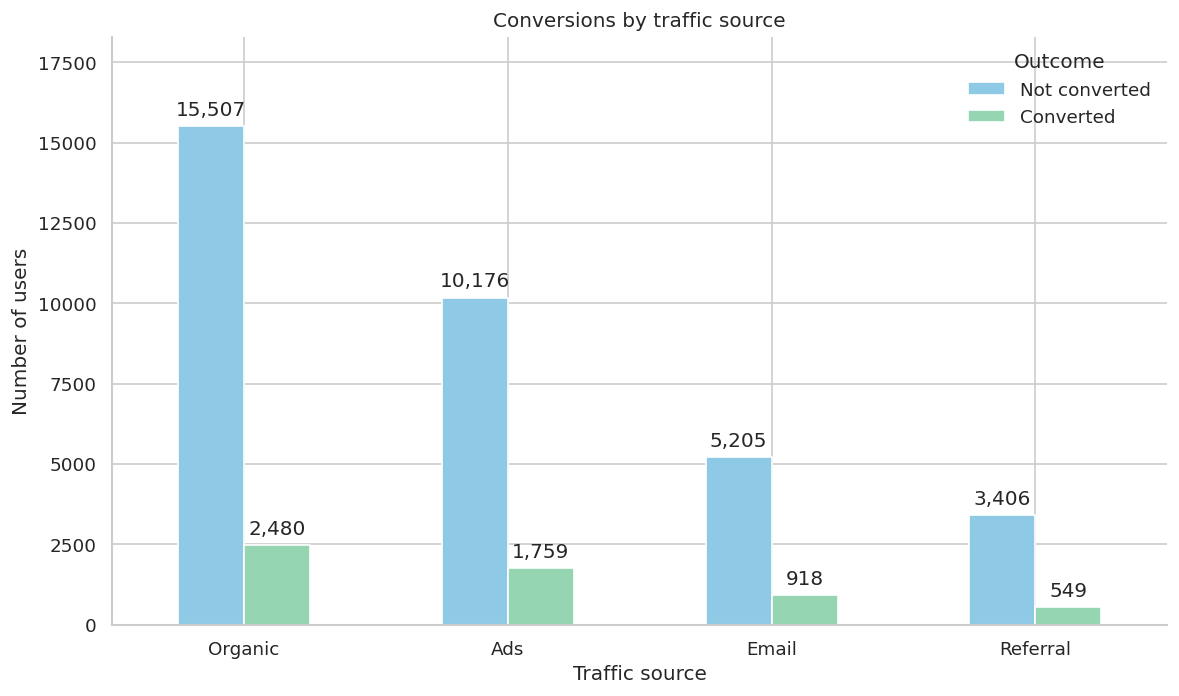

In [ ]:
plot_segment_counts(traffic_counts, "Conversions by traffic source", "Traffic source")

Organic accounts for the largest audience (**17,987 users**) and the largest number of buyers (**2,480**), followed by Ads (**11,935 users; 1,759 buyers**). Email and Referral have smaller audiences. Absolute buyer counts combine channel size and conversion efficiency; they should not be used alone to rank channel performance.

,Users,Not converted,Conversions,Conversion rate (%)
traffic_source,,,,
Email,6123,5205,918,14.99
Ads,11935,10176,1759,14.74
Referral,3955,3406,549,13.88
Organic,17987,15507,2480,13.79


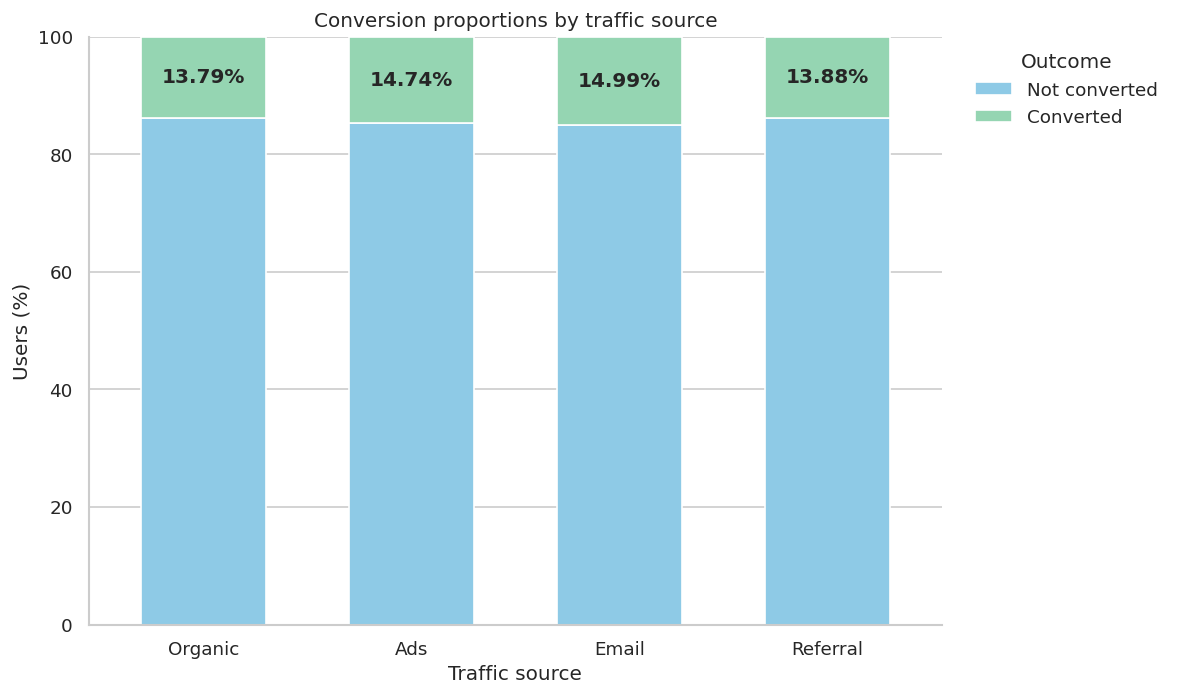

In [ ]:
display(traffic_summary[["Users", "Not converted", "Conversions", "Conversion rate (%)"]].round(2))
plot_segment_rates(traffic_counts, "Conversion proportions by traffic source", "Traffic source")

### Traffic source: expanded conversion-rate view

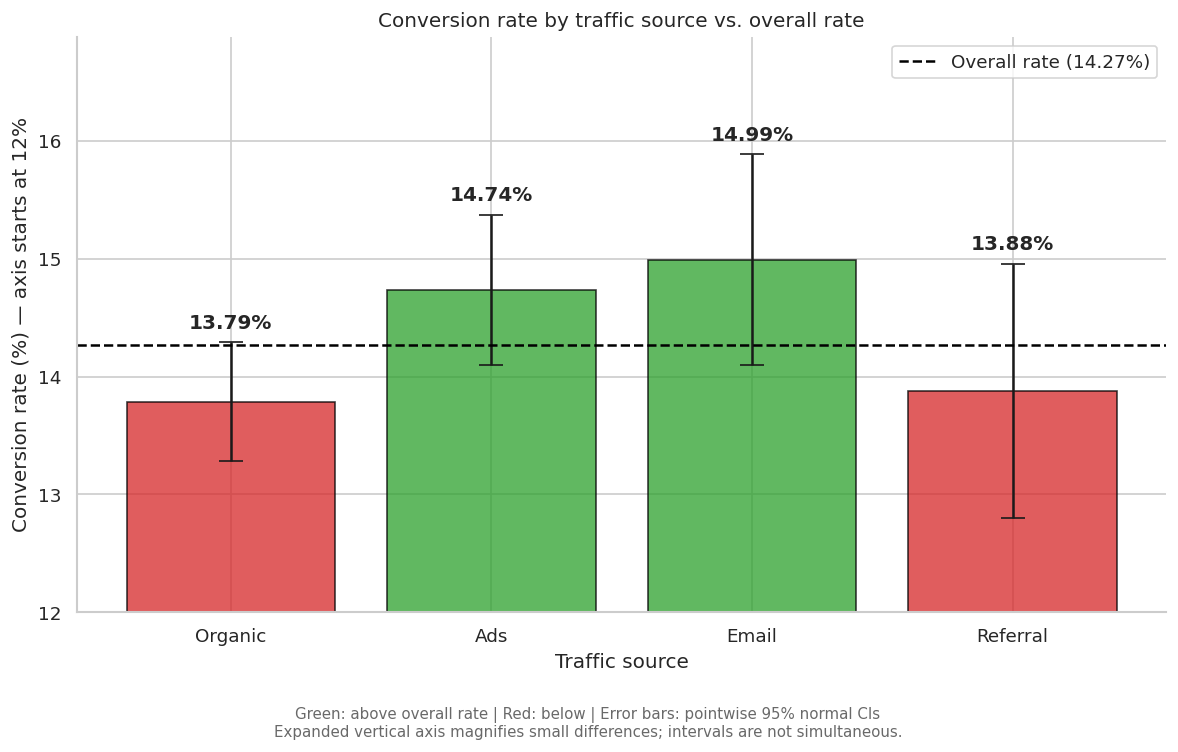

In [ ]:
traffic_plot_counts = traffic_counts.loc[traffic_counts.sum(axis=1).sort_values(ascending=False).index]
traffic_plot_totals = traffic_plot_counts.sum(axis=1)
traffic_plot_rates = traffic_plot_counts[1] / traffic_plot_totals * 100
global_conversion_pct = df["converted"].mean() * 100
traffic_plot_errors = stats.norm.ppf(0.975) * np.sqrt(
    (traffic_plot_rates / 100) * (1 - traffic_plot_rates / 100) / traffic_plot_totals
) * 100
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = ["#2ca02c" if rate > global_conversion_pct else "#d62728" for rate in traffic_plot_rates]
bars = ax.bar(traffic_plot_rates.index, traffic_plot_rates, yerr=traffic_plot_errors, capsize=7,
              color=colors, alpha=0.75, edgecolor="black")
ax.axhline(global_conversion_pct, color="black", linestyle="--", label=f"Overall rate ({global_conversion_pct:.2f}%)")
for bar, rate, error in zip(bars, traffic_plot_rates, traffic_plot_errors):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + error + 0.12, f"{rate:.2f}%", ha="center", fontweight="bold")
# Match the original 12% baseline where suitable; adapt if new data fall outside it.
axis_lower = max(0, min(12, np.floor((traffic_plot_rates - traffic_plot_errors).min() - 0.5)))
axis_upper = max(16.5, (traffic_plot_rates + traffic_plot_errors).max() + 1)
ax.set(ylim=(axis_lower, axis_upper), title="Conversion rate by traffic source vs. overall rate",
       xlabel="Traffic source", ylabel=f"Conversion rate (%) — axis starts at {axis_lower:g}%")
ax.legend(loc="upper right")
sns.despine()
plt.tight_layout()
fig.subplots_adjust(bottom=0.20)
fig.text(0.5, 0.04, "Green: above overall rate | Red: below | Error bars: pointwise 95% normal CIs\n"
         "Expanded vertical axis magnifies small differences; intervals are not simultaneous.",
         ha="center", fontsize=9, color="dimgray")
plt.show()

### Traffic-rate interpretation
The overall conversion rate is **14.265%**. Email is approximately **0.73 pp** above it, Ads **0.47 pp** above it, Referral **0.38 pp** below it, and Organic **0.48 pp** below it, using unrounded counts. Differences calculated from rounded display values can vary by 0.01 pp.

The pointwise 95% intervals touch or cross the overall-rate reference. This visual overlap is descriptive, **not a formal test against the overall rate**, because that rate includes each channel’s own observations. The omnibus chi-square result and very small Cramér’s V remain the statistical basis for the interpretation. The vertical axis starts at 12% for the original data, making small differences appear larger; the 100% stacked chart provides scale context.

Investigate channel efficiency alongside acquisition cost and profitability. The visual ranking does not establish causal or pairwise superiority.

### User type: volume and conversion efficiency

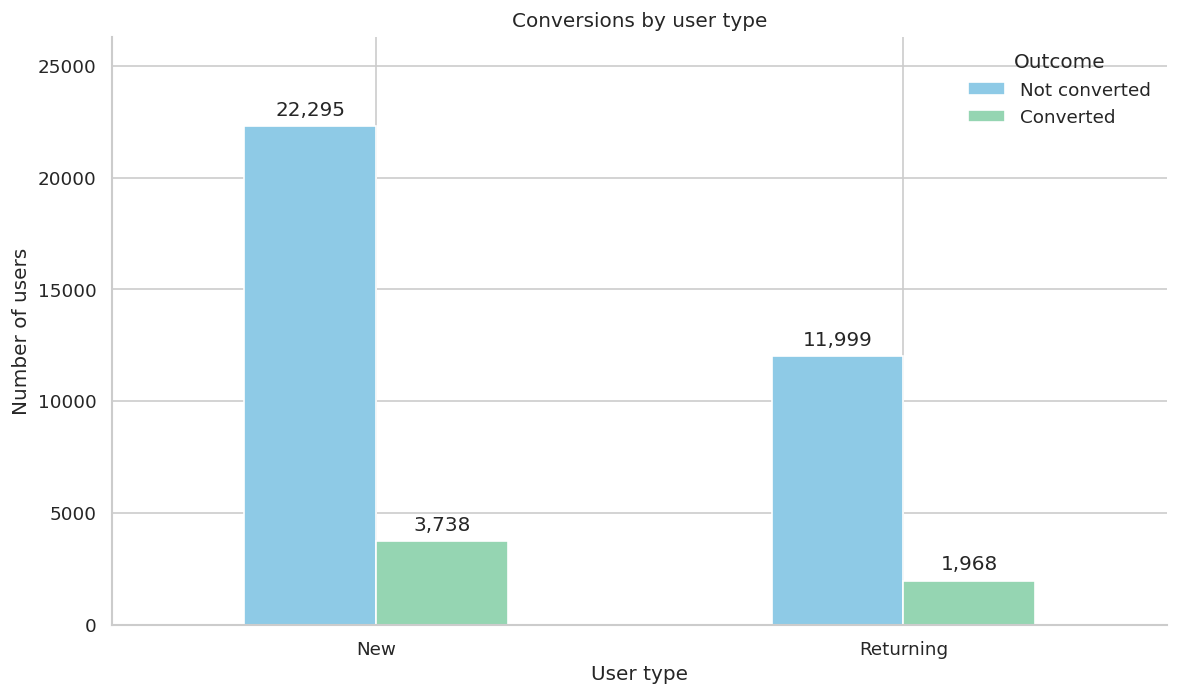

In [ ]:
plot_segment_counts(user_counts, "Conversions by user type", "User type")

New users form the larger segment (**26,033 vs. 13,967**) and contribute more conversions (**3,738 vs. 1,968**). This does not establish higher conversion efficiency. Compare the within-segment rates below.

,Users,Not converted,Conversions,Conversion rate (%)
user_type,,,,
New,26033,22295,3738,14.36
Returning,13967,11999,1968,14.09


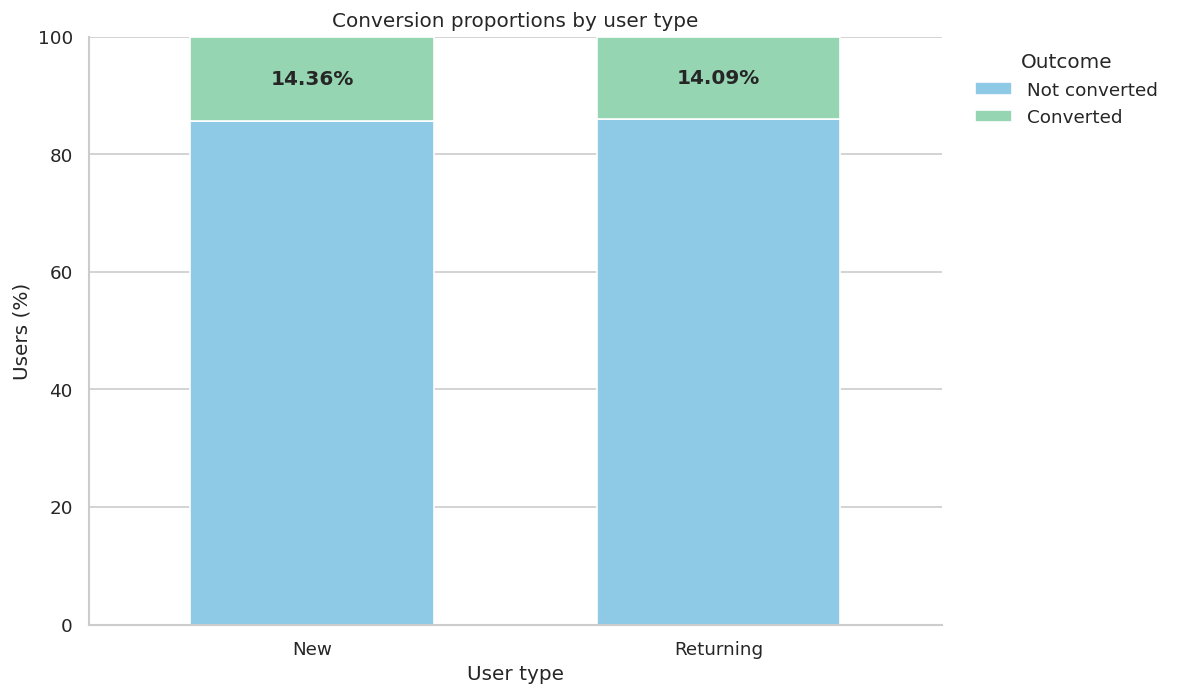

Observed rate range: 0.27 pp


In [ ]:
display(user_summary[["Users", "Not converted", "Conversions", "Conversion rate (%)"]].round(2))
print(f"Observed rate range: {user_summary['Conversion rate (%)'].max() - user_summary['Conversion rate (%)'].min():.2f} pp")
plot_segment_rates(user_counts, "Conversion proportions by user type", "User type")

The 100% stacked bars remove the visual influence of unequal segment sizes: New users convert at **14.36%** and Returning users at **14.09%**. Each green section represents buyers; the blue section represents non-buyers. The small observed difference agrees with the nonsignificant chi-square result (**p = 0.4736**). Other characteristics may also explain segment behavior; these descriptive comparisons alone do not support targeting decisions.

## Step 7: Evaluate revenue per exposed user
Revenue per exposed user includes zero spending and combines conversion with buyer spending. It is the main economic outcome for the recommendation, although the original experimental plan does not establish that it was prespecified as the primary endpoint.

The distribution has a large mass at zero and a right tail. Use **10,000 within-group bootstrap resamples** to obtain percentile 95% CIs for the mean difference and relative lift, with Welch’s test as a complementary mean comparison. The bootstrap does not assume a parametric distribution, but it still relies on representative, independent observations and does not remove design bias. Large group sizes support the mean approximation; they do not guarantee it in every setting.

**H₀:** mean revenue per exposed user is equal in A and B. **H₁:** it differs. Mann–Whitney is not used as a mean-revenue test because its rank estimand does not answer this economic question. A bootstrap confidence interval is reported without treating an uncentered resampling tail fraction as a calibrated null-hypothesis p-value.

In [ ]:
revenue_a = df.loc[df["landing"].eq("A"), "spend"].to_numpy()
revenue_b = df.loc[df["landing"].eq("B"), "spend"].to_numpy()
revenue_mean_a, revenue_mean_b = revenue_a.mean(), revenue_b.mean()
revenue_difference = revenue_mean_b - revenue_mean_a
revenue_lift_pct = (revenue_mean_b / revenue_mean_a - 1) * 100
for label, values in [("A", revenue_a), ("B", revenue_b)]:
    print(f"Page {label}: n={len(values):,}; zero revenue={(values == 0).mean():.2%}; "
          f"mean={values.mean():.4f}; median={np.median(values):.2f}; skewness={stats.skew(values):.2f}")
revenue_rng = np.random.default_rng(RANDOM_SEED)
revenue_boot_differences = np.empty(N_BOOTSTRAP)
revenue_boot_lifts = np.empty(N_BOOTSTRAP)
for iteration in range(N_BOOTSTRAP):
    boot_mean_a = revenue_rng.choice(revenue_a, len(revenue_a), replace=True).mean()
    boot_mean_b = revenue_rng.choice(revenue_b, len(revenue_b), replace=True).mean()
    revenue_boot_differences[iteration] = boot_mean_b - boot_mean_a
    revenue_boot_lifts[iteration] = (boot_mean_b / boot_mean_a - 1) * 100 if boot_mean_a > 0 else np.nan
revenue_difference_ci = np.percentile(revenue_boot_differences, [2.5, 97.5])
if not np.isfinite(revenue_boot_lifts).all():
    raise ValueError("Relative-lift bootstrap is undefined for a zero-revenue control resample.")
revenue_lift_ci = np.percentile(revenue_boot_lifts, [2.5, 97.5])
revenue_t, revenue_p = stats.ttest_ind(revenue_a, revenue_b, equal_var=False)
revenue_results = pd.DataFrame({
    "Method": ["Bootstrap percentile 95% CI", "Welch (A first)"],
    "Result": [f"Difference [{revenue_difference_ci[0]:.4f}, {revenue_difference_ci[1]:.4f}] CU; "
               f"lift [{revenue_lift_ci[0]:.2f}%, {revenue_lift_ci[1]:.2f}%]", f"t = {revenue_t:.4f}"],
    "p-value": ["Not calculated from the percentile bootstrap", f"{revenue_p:.2e}"]
})
print(f"Revenue per user: A={revenue_mean_a:.4f} CU; B={revenue_mean_b:.4f} CU")
print(f"Difference B − A: {revenue_difference:+.4f} CU; relative lift: {revenue_lift_pct:+.2f}%")
display(revenue_results)
print("Welch's t is negative when B has higher mean revenue because A is passed first.")
if revenue_p < ALPHA and revenue_difference_ci[0] > 0:
    print("The mean-revenue comparison and bootstrap interval support higher revenue for B.")
elif revenue_p < ALPHA and revenue_difference_ci[1] < 0:
    print("The mean-revenue comparison and bootstrap interval support higher revenue for A.")
else:
    print("The two procedures do not jointly establish a direction at the chosen thresholds.")

Page A: n=19,982; zero revenue=87.43%; mean=7.6794; median=0.00; skewness=3.47
Page B: n=20,018; zero revenue=84.04%; mean=10.9688; median=0.00; skewness=2.85
Revenue difference B − A: +3.2894 CU; relative lift: +42.83%
Bootstrap percentile 95% CI, difference: [2.7859, 3.7862] CU
Bootstrap percentile 95% CI, relative lift: [+35.30%, +50.79%]
Welch t (A first): -12.8438; p-value: 1.11e-37
No null-hypothesis p-value is reported from the uncentered percentile bootstrap.


### Revenue conclusion
B generated **10.97 CU per exposed user**, compared with **7.68 CU** for A: an observed difference of **3.29 CU (+42.83%)**. The bootstrap 95% CI is **[2.79, 3.79] CU**, or **[35.30%, 50.79%]** for relative lift. Welch’s test gives **p = 1.11 × 10⁻³⁷**.

The interval provides an uncertainty range under the sampling and design assumptions; its lower endpoint is **not a guaranteed minimum future gain**. The evidence supports B’s economic performance in this experiment, while implementation cost, margins, and longer-term effects remain unmeasured.

## Step 8: Executive summary and recommendation
### Main finding
Across **40,000 users observed over January 1–28, 2026**, page B achieved higher conversion, higher average spending among buyers, and higher revenue per exposed user. No sample-ratio mismatch or composition imbalance was detected in the reported checks.

| Metric | Page A | Page B | Observed B − A effect |
|---|---:|---:|---:|
| Exposed users | 19,982 | 20,018 | +36 users |
| Conversions | 2,512 | 3,194 | +682 conversions |
| Conversion rate | 12.57% | 15.96% | +3.38 pp; +26.92% relative |
| Average buyer spending (CU/buyer) | 61.09 | 68.75 | +7.66 CU; approximately +12.5% relative |
| Revenue per exposed user (CU/user) | 7.68 | 10.97 | +3.29 CU; +42.83% relative |

Differences are calculated before rounding. Raw conversion counts reflect slightly different group sizes; the rate comparison is the appropriate normalized effect. The three page comparisons are statistically significant at the nominal 5% level. They are related outcomes, not three independent replications.

### Traffic-source findings
Organic contributes the most conversions (**2,480; 43.46%** of the total). Email has the highest observed conversion rate (**14.99%**), followed by Ads (**14.74%**), Referral (**13.88%**), and Organic (**13.79%**). The association is small (**V = 0.0147**) and only nominally significant (**p = 0.03414**). It does not, by itself, justify a marketing-budget change.

### User-type findings
New and Returning users have similar observed conversion rates (**14.36% vs. 14.09%**), with no statistically significant association (**p = 0.4736**). B has higher descriptive rates in both segments. These findings alone do not justify different page strategies by user type, and they do not prove equal treatment effects.

### Recommended actions
1. **Proceed with a monitored rollout of page B**, conditional on confirming sound random assignment and acceptable implementation costs. Revenue per exposed user provides the strongest business justification: **+42.83% observed lift**, with a bootstrap 95% interval of **+35.30% to +50.79%** under the analysis assumptions.
2. **Evaluate acquisition channels economically** before reallocating budget. Include acquisition cost, margins, and revenue by channel rather than relying on observed conversion rates alone.
3. **Avoid introducing user-type-specific conversion strategies based solely on this analysis.** Use a formal interaction test and adequate power if differentiated treatment effects become a business question.
4. **Monitor performance after rollout:** conversion, revenue per exposed user, buyer spending, and relevant operational guardrails. Assess whether gains persist with future traffic and seasonal changes.

### Limitations
The analysis assumes valid random assignment, representative exposure, and independent observations; the dataset checks cannot verify every design assumption. The experiment spans only **28 days**. Buyer-only spending conditions on a treatment-affected outcome. Traffic and user-type comparisons are observational and exploratory; no formal treatment-interaction test was performed. Multiple hypotheses were examined without a prespecified multiplicity plan, so the traffic-source p-value needs particular caution. Cost, margin, retention, and implementation-risk data are unavailable. A 95% interval is not a performance guarantee.

**Final recommendation:** choose **page B**, subject to design verification and a monitored rollout. Base the decision on its higher observed conversion and revenue per exposed user, while treating channel rankings and user-type differences as exploratory evidence.